# 04 — Time classes

**Concept:** the network tariff prices each kWh by one of four **time classes**: peak (HP) or off-peak (HC) hours, in the high season (November to March) or the low season (April to October). A `TimeClassCalendar` gives, for every step of a grid, the **share** of that step in each class.

**You will learn:** where off-peak hours come from (the contract), why shares are fractions rather than labels, how seasons and daylight-saving days behave, and how a year of consumption splits into the four classes.

## The contract holds the off-peak hours

Off-peak hours belong to each connection: Enedis sets 8 of them a day, often split in two windows. They are printed on the bill, and `OffPeakHours.parse` reads them as written there. The contract checks the tariff rules: a time-of-use network option (`CU4`, `MU4`, …) or a peak/off-peak supply option needs exactly 8 hours.

In [1]:
from datetime import date, datetime, timedelta
from decimal import Decimal
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt

from myenergy.adapters.profiles.synthetic import SyntheticProfileSource
from myenergy.adapters.rates.toml_files import TomlRateSource, packaged_rate_files
from myenergy.domain.contract import Contract, Fta, SupplyOption
from myenergy.domain.errors import ContractError
from myenergy.domain.profiles import Nominal, ProfileRef, Shaped
from myenergy.domain.rates import RateKey
from myenergy.domain.time import TimeGrid
from myenergy.domain.time_classes import CLASSES, OffPeakHours, TimeClass
from myenergy.engine.profiles import ProfileResolver

PARIS = ZoneInfo("Europe/Paris")
hours = OffPeakHours.parse("1H30-7H30 13H30-15H30")  # as printed on a bill
contract = Contract(
    subscribed_kva=Decimal(6),
    supply_option=SupplyOption.PEAK_OFFPEAK,
    fta=Fta.CU4,
    off_peak=hours,
)
print(contract.off_peak, f"({contract.off_peak.hours:g} h a day)")

01:30-07:30 13:30-15:30 (8 h a day)


In [2]:
try:
    Contract(subscribed_kva=Decimal(6), supply_option=SupplyOption.PEAK_OFFPEAK,
             fta=Fta.CU4, off_peak=OffPeakHours.parse("22:00-05:00"))
except ContractError as error:
    print(error)

CU4 with the hp-hc option needs 8 off-peak hours a day, got 22:00-05:00 (7 h)


## Shares, not labels

On a 30-minute grid every step falls in one class. Each row of `shares` holds the four shares, in the order HPH, HCH, HPB, HCB.

In [3]:
calendar = contract.calendar()


def day(month: int, dom: int, minutes: int, days: int = 1) -> TimeGrid:
    start = datetime(2026, month, dom, tzinfo=PARIS)
    return TimeGrid(start=start, end=start + timedelta(days=days),
                    step=timedelta(minutes=minutes))


def labels(grid: TimeGrid) -> str:
    shares = calendar.weights(grid).shares
    return " ".join("/".join(c for c, s in zip(CLASSES, row) if s > 0) for row in shares)


print(labels(day(1, 15, 30)))

HPH HPH HPH HCH HCH HCH HCH HCH HCH HCH HCH HCH HCH HCH HCH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HCH HCH HCH HCH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH HPH


With 60-minute steps, the steps 01:00–02:00 and 13:00–14:00 straddle a window edge (01:30, 13:30). Rather than guess a label, the calendar splits them by time: half peak, half off-peak. That is what keeps the energy per class exact, whatever the step.

In [4]:
hourly = calendar.weights(day(1, 15, 60))
for i in (0, 1, 2, 13, 14):
    print(f"{hourly.grid.local(i):%H:%M}", hourly.shares[i])

00:00 [1. 0. 0. 0.]
01:00 [0.5 0.5 0.  0. ]
02:00 [0. 1. 0. 0.]
13:00 [0.5 0.5 0.  0. ]
14:00 [0. 1. 0. 0.]


## Seasons change at local midnight

The season follows the local date: on hourly steps, 31 March is in the high season (HPH, HCH) and 1 April in the low season (HPB, HCB). Steps that straddle a window edge show both classes.

In [5]:
print(labels(day(3, 31, 60, days=2)))

HPH HPH/HCH HCH HCH HCH HCH HCH HPH/HCH HPH HPH HPH HPH HPH HPH/HCH HCH HPH/HCH HPH HPH HPH HPH HPH HPH HPH HPH HPB HPB/HCB HCB HCB HCB HCB HCB HPB/HCB HPB HPB HPB HPB HPB HPB/HCB HCB HPB/HCB HPB HPB HPB HPB HPB HPB HPB HPB


## Daylight-saving days

Shares are worked out in real (UTC) time. The window 01:30–07:30 loses an hour on the spring day, when clocks jump from 02:00 to 03:00, and gains one on the autumn day.

In [6]:
for month, dom in ((1, 15), (3, 29), (10, 25)):
    weights = calendar.weights(day(month, dom, 15))
    off_peak = (weights.shares[:, 1] + weights.shares[:, 3]).sum() / 4
    print(f"2026-{month:02}-{dom:02}: {len(weights.grid) / 4:g} h in the day, "
          f"{off_peak:g} h off-peak")

2026-01-15: 24 h in the day, 8 h off-peak
2026-03-29: 23 h in the day, 7 h off-peak
2026-10-25: 25 h in the day, 9 h off-peak


## A year of consumption, by class

`split` turns a power or energy series into kWh per class. The four values always add up to the total. Here, a synthetic household using 3,500 kWh a year, over the TURPE 7 year from 1 August 2025.

In [7]:
year = TimeGrid(start=datetime(2025, 8, 1, tzinfo=PARIS),
                end=datetime(2026, 8, 1, tzinfo=PARIS), step=timedelta(minutes=30))
resolver = ProfileResolver({"synthetic": SyntheticProfileSource(seed=1)})
load = resolver.power(
    Shaped(ref=ProfileRef(source="synthetic", key="household"),
           scaling=Nominal(annual_kwh=3500)),
    year,
)
by_class = calendar.weights(year).split(load)
for time_class, kwh in by_class.items():
    print(f"{time_class}: {kwh:7.1f} kWh")
print(f"total: {sum(by_class.values()):.1f} kWh (load: {load.energy().total():.1f} kWh)")

HPH:  1234.2 kWh
HCH:   482.7 kWh
HPB:  1332.7 kWh
HCB:   450.3 kWh
total: 3500.0 kWh (load: 3500.0 kWh)


Why it matters: the network charge per kWh differs by class. With the CU4 rates in force from 1 August 2025 (from the packaged rate tables), a peak kWh in winter costs the network part about four and a half times a peak kWh in summer.

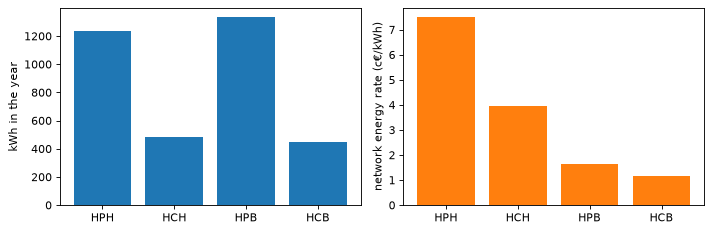

In [8]:
rates = TomlRateSource(packaged_rate_files())
on = date(2025, 8, 1)
cost = {}
for time_class in TimeClass:
    key = RateKey.of("turpe.withdrawal.energy", segment=contract.segment,
                     fta=contract.fta.value, time_class=time_class.value)
    cost[time_class] = float(rates.history(key).on(on).value)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3), dpi=80)
left.bar([c.value for c in TimeClass], [by_class[c] for c in TimeClass])
left.set_ylabel("kWh in the year")
right.bar([c.value for c in TimeClass], [100 * cost[c] for c in TimeClass], color="tab:orange")
right.set_ylabel("network energy rate (c€/kWh)")
fig.tight_layout()

**Next:** the anatomy of a bill (M2) stacks the network tariff, the taxes and the supply price on top of these classes.